# 🌊 FloodFrame — Kaggle Training Notebook v2

Binary classification MVP: **NORMAL / NON-FLOOD vs FLOOD / GENANGAN**.

Datasets:
- Flood: `/kaggle/input/datasets/hhrclemson/flooding-image-dataset`
- Normal: `/kaggle/input/datasets/solesensei/solesensei_bdd100k`

This notebook is designed to run end-to-end during **Save Version** on Kaggle.

> Important: model confidence is **not** flood severity or water depth.

In [1]:
from pathlib import Path
import os, json, random, shutil, math, zipfile, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings('ignore')
print('='*80)
print('FLOODFRAME - ENVIRONMENT CHECK')
print('='*80)
print('Torch version  :', torch.__version__)
print('CUDA available :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU            :', torch.cuda.get_device_name(0))
else:
    print('[WARNING] Kaggle -> Settings -> Accelerator -> GPU')

FLOODFRAME - ENVIRONMENT CHECK
Torch version  : 2.11.0+cu128
CUDA available : True
GPU            : Tesla T4


In [2]:
SEED = 42
FLOOD_ROOT = Path('/kaggle/input/datasets/hhrclemson/flooding-image-dataset')
NORMAL_ROOT = Path('/kaggle/input/datasets/solesensei/solesensei_bdd100k')
WORK_DIR = Path('/kaggle/working/floodframe')
PREPARED_DIR = WORK_DIR / 'prepared_dataset'
OUTPUT_DIR = WORK_DIR / 'outputs'
MODEL_DIR = OUTPUT_DIR / 'models'
ASSET_DIR = OUTPUT_DIR / 'assets'
REPORT_DIR = OUTPUT_DIR / 'reports'
IMAGE_EXTENSIONS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
IMAGE_SIZE = 224
BATCH_SIZE = 64
HEAD_EPOCHS = 4
FINETUNE_EPOCHS = 8
HEAD_LR = 1e-3
FINETUNE_LR = 1e-4
MAX_IMAGES_PER_CLASS = 6000
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
NUM_WORKERS = 2
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
for p in [WORK_DIR, PREPARED_DIR, OUTPUT_DIR, MODEL_DIR, ASSET_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)
print('Flood root :', FLOOD_ROOT)
print('Normal root:', NORMAL_ROOT)

Flood root : /kaggle/input/datasets/hhrclemson/flooding-image-dataset
Normal root: /kaggle/input/datasets/solesensei/solesensei_bdd100k


In [3]:
def find_images(root: Path):
    root = Path(root)
    if not root.exists(): return []
    return sorted([p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS])

def print_tree(root: Path, max_depth=3, max_items=20):
    root=Path(root)
    if not root.exists():
        print('[ERROR] Missing:', root); return
    print(root)
    def walk(cur, depth):
        if depth>max_depth: return
        items=sorted(cur.iterdir(), key=lambda p:(p.is_file(),p.name.lower()))
        for item in items[:max_items]:
            print('  '*depth + ('📁 ' if item.is_dir() else '📄 ') + item.name)
            if item.is_dir(): walk(item, depth+1)
        if len(items)>max_items: print('  '*depth + f'... +{len(items)-max_items} items')
    walk(root,1)

def show_samples(paths, title, n=12, cols=4):
    paths=list(paths)
    if not paths: return
    selected=random.sample(paths, min(n,len(paths)))
    rows=math.ceil(len(selected)/cols)
    plt.figure(figsize=(15,4*rows))
    for i,path in enumerate(selected,1):
        try:
            img=Image.open(path).convert('RGB')
            ax=plt.subplot(rows,cols,i); ax.imshow(img); ax.set_title(path.name[:36]); ax.axis('off')
        except Exception as e: print('[WARNING]', path, e)
    plt.suptitle(title, fontsize=16); plt.tight_layout(); plt.show()

## 1. Inspect both datasets

/kaggle/input/datasets/hhrclemson/flooding-image-dataset
  📁 Annotation
    📄 flood_10.json
    📄 flood_109.json
    📄 flood_11.json
    📄 flood_118.json
    📄 flood_119.json
    📄 flood_12.json
    📄 flood_120.json
    📄 flood_121.json
    📄 flood_13.json
    📄 flood_15.json
    📄 flood_16.json
    📄 flood_21.json
    📄 flood_23.json
    📄 flood_26.json
    📄 flood_28.json
    📄 flood_37.json
    📄 flood_6.json
    📄 flood_60.json
    📄 flood_61.json
    📄 flood_62.json
    ... +5 items
  📁 Flood Images
    📄 flood_0.jpg
    📄 flood_1.jpg
    📄 flood_10.jpg
    📄 flood_100.jpg
    📄 Flood_1000.jpg
    📄 flood_1001.jpg
    📄 Flood_1002.jpg
    📄 flood_1003.jpg
    📄 flood_1004.jpg
    📄 flood_1005.jpg
    📄 flood_1006.jpg
    📄 flood_1007.jpg
    📄 flood_1008.jpg
    📄 flood_1009.jpg
    📄 flood_101.jpg
    📄 flood_1010.jpg
    📄 Flood_1011.jpg
    📄 Flood_1012.jpg
    📄 flood_1013.jpg
    📄 flood_1014.jpg
    ... +9276 items
Flood images found: 9296


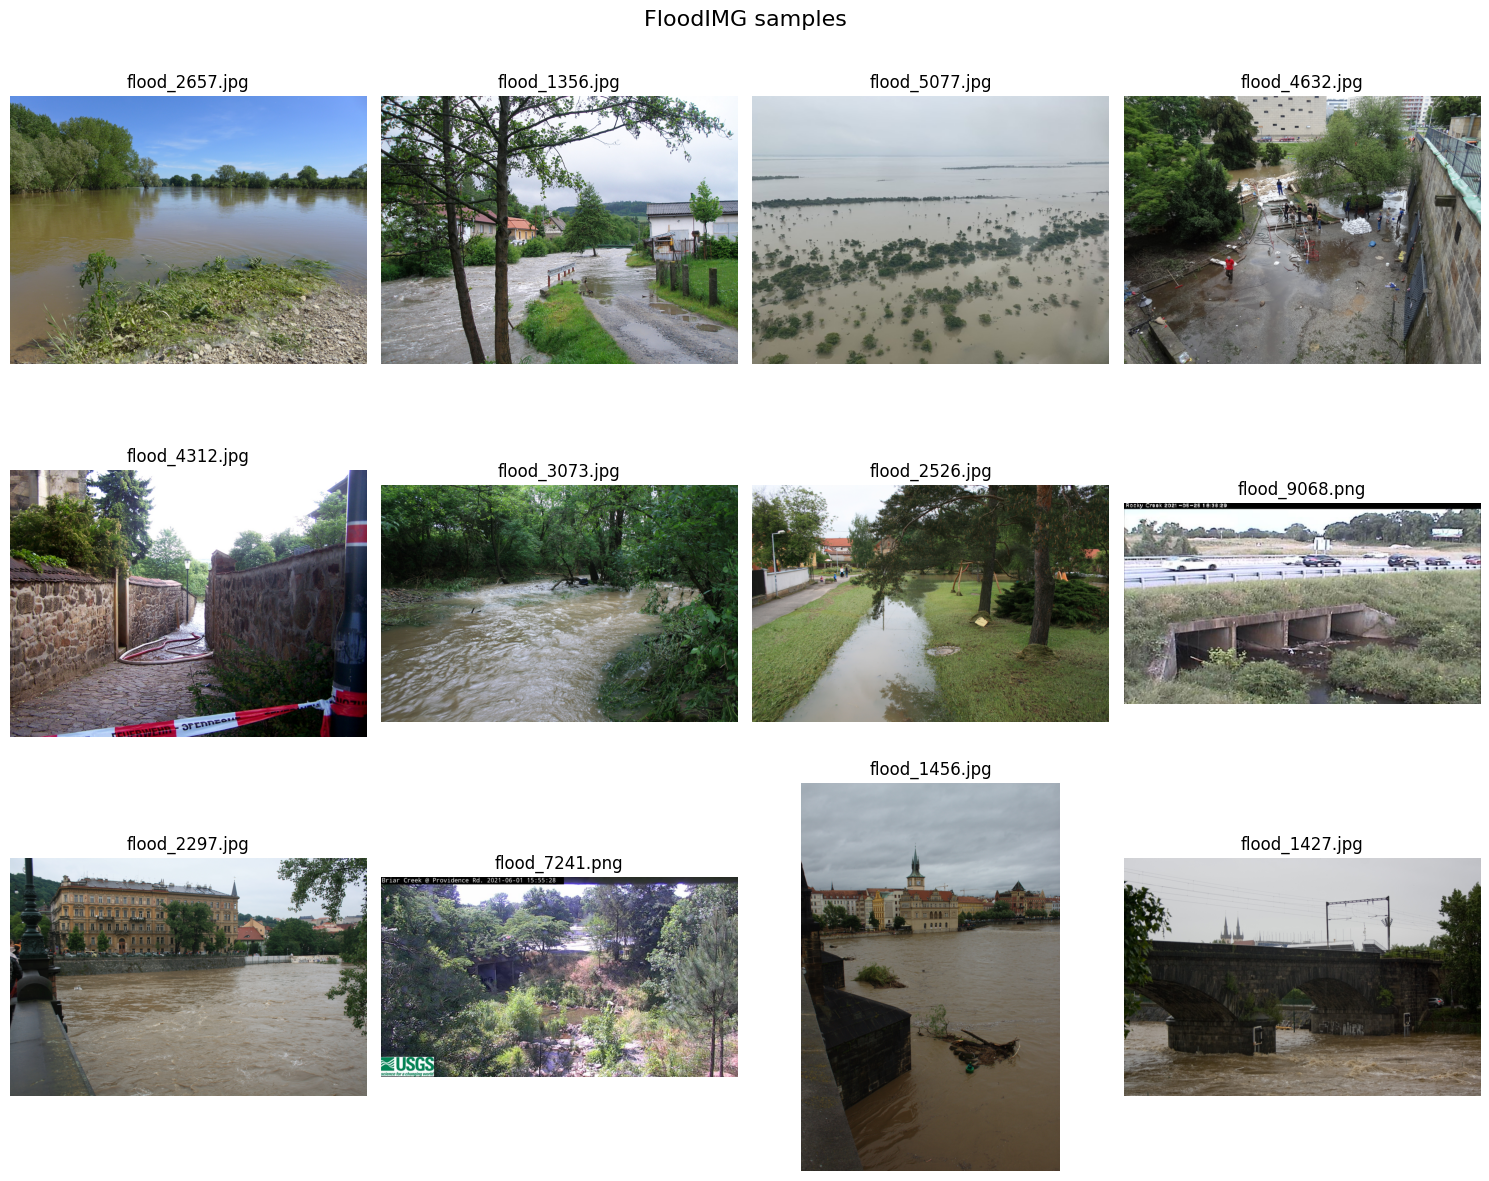

In [4]:
if not FLOOD_ROOT.exists(): raise FileNotFoundError(FLOOD_ROOT)
if not NORMAL_ROOT.exists(): raise FileNotFoundError(NORMAL_ROOT)
print_tree(FLOOD_ROOT, max_depth=2)
flood_images = find_images(FLOOD_ROOT)
print('Flood images found:', len(flood_images))
if not flood_images: raise RuntimeError('No flood images found')
show_samples(flood_images, 'FloodIMG samples')

/kaggle/input/datasets/solesensei/solesensei_bdd100k
  📁 bdd100k
    📁 bdd100k
      📁 images
  📁 bdd100k_labels_release
    📁 bdd100k
      📁 labels
  📁 bdd100k_seg
    📁 bdd100k
      📁 seg
BDD100K images found: 136000


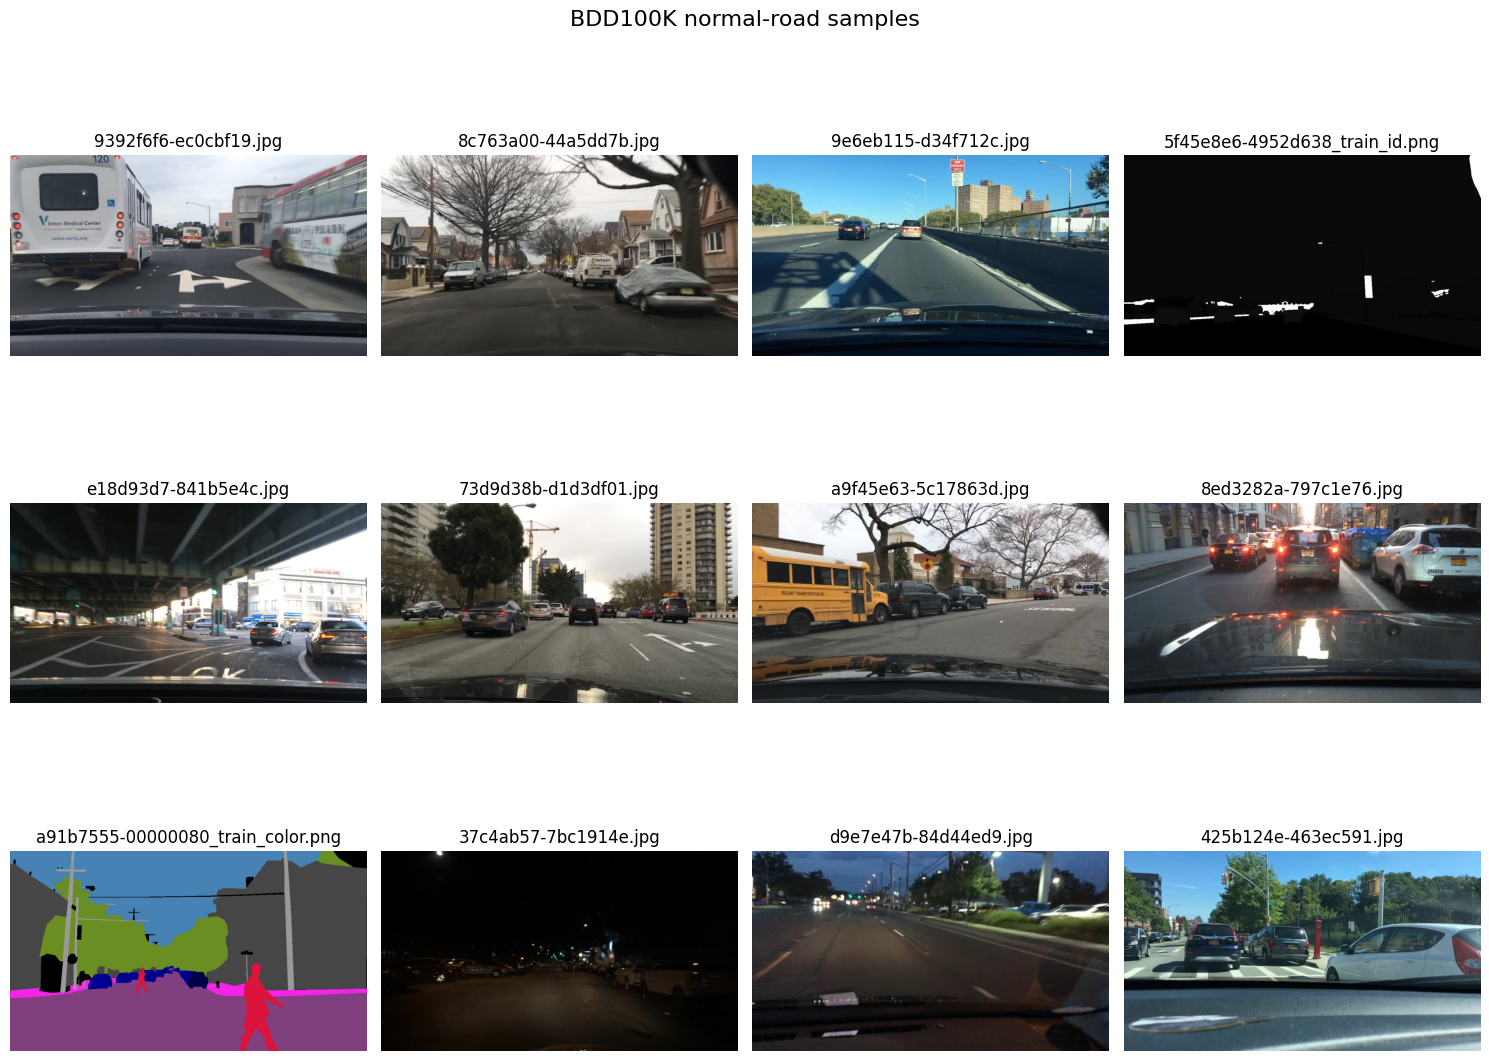

In [5]:
print_tree(NORMAL_ROOT, max_depth=3)
normal_images_all = find_images(NORMAL_ROOT)
print('BDD100K images found:', len(normal_images_all))
if not normal_images_all: raise RuntimeError('No BDD100K images found')
show_samples(normal_images_all, 'BDD100K normal-road samples')

## 2. Grounding summary

In [6]:
grounding_summary={
 'project':'FloodFrame','task':'binary_image_classification','classes':['flood','normal'],
 'flood_source':str(FLOOD_ROOT),'normal_source':str(NORMAL_ROOT),
 'flood_images_found':len(flood_images),'normal_images_found':len(normal_images_all),
 'limitations':[
  'Flood and normal images come from different source datasets.',
  'Dataset-source bias may inflate evaluation metrics.',
  'Real CCTV stream performance is not validated yet.',
  'Flood severity and water depth are not modeled.',
  'Temporal persistence is not modeled.'
 ]}
print(json.dumps(grounding_summary, indent=2))
with open(REPORT_DIR/'grounding_summary.json','w',encoding='utf-8') as f: json.dump(grounding_summary,f,indent=2)

{
  "project": "FloodFrame",
  "task": "binary_image_classification",
  "classes": [
    "flood",
    "normal"
  ],
  "flood_source": "/kaggle/input/datasets/hhrclemson/flooding-image-dataset",
  "normal_source": "/kaggle/input/datasets/solesensei/solesensei_bdd100k",
  "flood_images_found": 9296,
  "normal_images_found": 136000,
  "limitations": [
    "Flood and normal images come from different source datasets.",
    "Dataset-source bias may inflate evaluation metrics.",
    "Real CCTV stream performance is not validated yet.",
    "Flood severity and water depth are not modeled.",
    "Temporal persistence is not modeled."
  ]
}


## 3. Build balanced dataset (up to 6,000 images per class)

In [7]:
if PREPARED_DIR.exists(): shutil.rmtree(PREPARED_DIR)
for split in ['train','val','test']:
    for cls in ['flood','normal']:
        (PREPARED_DIR/split/cls).mkdir(parents=True, exist_ok=True)
usable=min(len(flood_images),len(normal_images_all),MAX_IMAGES_PER_CLASS)
if usable<500: raise RuntimeError(f'Too little data: {usable} per class')
print('Usable per class:',usable,'Total:',usable*2)
rng=random.Random(SEED)
flood_selected=rng.sample(flood_images,usable)
normal_selected=rng.sample(normal_images_all,usable)
def split_paths(paths):
    paths=list(paths); rng.shuffle(paths); n=len(paths); a=int(n*TRAIN_RATIO); b=int(n*VAL_RATIO)
    return paths[:a], paths[a:a+b], paths[a+b:]
ft,fv,fs=split_paths(flood_selected); nt,nv,ns=split_paths(normal_selected)
split_map={('train','flood'):ft,('val','flood'):fv,('test','flood'):fs,('train','normal'):nt,('val','normal'):nv,('test','normal'):ns}
def copy_images(paths,dst,prefix):
    copied=skipped=0
    for i,src in enumerate(paths):
        try:
            shutil.copy2(src,dst/f'{prefix}_{i:06d}{src.suffix.lower()}'); copied+=1
        except Exception: skipped+=1
    return copied,skipped
rows=[]
for (split,cls),paths in split_map.items():
    c,s=copy_images(paths,PREPARED_DIR/split/cls,cls); rows.append({'split':split,'class':cls,'copied':c,'skipped':s})
display(pd.DataFrame(rows))

Usable per class: 6000 Total: 12000


,split,class,copied,skipped
0,train,flood,4200,0
1,val,flood,900,0
2,test,flood,900,0
3,train,normal,4200,0
4,val,normal,900,0
5,test,normal,900,0


In [8]:
dist=[]
for split in ['train','val','test']:
    for cls in ['flood','normal']:
        dist.append({'split':split,'class':cls,'images':len(find_images(PREPARED_DIR/split/cls))})
distribution_df=pd.DataFrame(dist)
display(distribution_df)
display(distribution_df.pivot(index='split',columns='class',values='images'))
distribution_df.to_csv(REPORT_DIR/'dataset_distribution.csv',index=False)
if distribution_df['images'].min()==0: raise RuntimeError('Empty split/class detected')

,split,class,images
0,train,flood,4200
1,train,normal,4200
2,val,flood,900
3,val,normal,900
4,test,flood,900
5,test,normal,900


class,flood,normal
split,,
test,900,900
train,4200,4200
val,900,900


## 4. Pretrained EfficientNet-B0 (safe fallback)

In [9]:
PRETRAINED_WEIGHTS=None
try:
    PRETRAINED_WEIGHTS=EfficientNet_B0_Weights.DEFAULT
    _tmp=efficientnet_b0(weights=PRETRAINED_WEIGHTS); del _tmp
    print('[OK] Pretrained ImageNet weights available.')
except Exception as e:
    PRETRAINED_WEIGHTS=None
    print('[WARNING] Pretrained weights unavailable:',e)
    print('Continuing with weights=None so Save Version can still finish.')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 127MB/s] 


[OK] Pretrained ImageNet weights available.


## 5. Data pipeline

In [10]:
MEAN=[0.485,0.456,0.406]; STD=[0.229,0.224,0.225]
train_transform=transforms.Compose([
 transforms.Resize((256,256)), transforms.RandomResizedCrop(IMAGE_SIZE,scale=(0.80,1.0)),
 transforms.RandomHorizontalFlip(0.5), transforms.RandomRotation(8),
 transforms.ColorJitter(brightness=0.15,contrast=0.15,saturation=0.10),
 transforms.ToTensor(), transforms.Normalize(MEAN,STD)])
val_transform=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
train_dataset=datasets.ImageFolder(PREPARED_DIR/'train',transform=train_transform)
val_dataset=datasets.ImageFolder(PREPARED_DIR/'val',transform=val_transform)
test_dataset=datasets.ImageFolder(PREPARED_DIR/'test',transform=val_transform)
class_names=train_dataset.classes; class_to_idx=train_dataset.class_to_idx
print('Classes:',class_names,'Mapping:',class_to_idx)
pin=torch.cuda.is_available()
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=pin)
val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=pin)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=pin)
print(len(train_dataset),len(val_dataset),len(test_dataset))

Classes: ['flood', 'normal'] Mapping: {'flood': 0, 'normal': 1}
8400 1800 1800


## 6. Build model

In [11]:
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=efficientnet_b0(weights=PRETRAINED_WEIGHTS)
in_features=model.classifier[1].in_features
model.classifier[1]=nn.Linear(in_features,len(class_names))
model=model.to(DEVICE)
criterion=nn.CrossEntropyLoss()
def freeze_backbone(m):
    for p in m.features.parameters(): p.requires_grad=False
    for p in m.classifier.parameters(): p.requires_grad=True
def unfreeze_last(m,n=3):
    for p in m.features.parameters(): p.requires_grad=False
    for block in list(m.features.children())[-n:]:
        for p in block.parameters(): p.requires_grad=True
    for p in m.classifier.parameters(): p.requires_grad=True
freeze_backbone(model)
print('Device:',DEVICE)

Device: cuda


## 7. Training helpers

In [12]:
AMP=torch.cuda.is_available()
try: scaler=torch.amp.GradScaler('cuda',enabled=AMP)
except Exception: scaler=torch.cuda.amp.GradScaler(enabled=AMP)
from contextlib import nullcontext
def autocast_ctx():
    if not AMP: return nullcontext()
    try: return torch.amp.autocast(device_type='cuda',dtype=torch.float16)
    except Exception: return torch.cuda.amp.autocast()
def train_epoch(loader,opt):
    model.train(); loss_sum=0.; ys=[]; ps=[]
    for x,y in loader:
        x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True); opt.zero_grad(set_to_none=True)
        with autocast_ctx(): logits=model(x); loss=criterion(logits,y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        pred=logits.argmax(1); loss_sum+=loss.item()*x.size(0); ys+=y.detach().cpu().tolist(); ps+=pred.detach().cpu().tolist()
    return loss_sum/len(loader.dataset),accuracy_score(ys,ps),f1_score(ys,ps,average='macro',zero_division=0)
@torch.no_grad()
def eval_epoch(loader):
    model.eval(); loss_sum=0.; ys=[]; ps=[]
    for x,y in loader:
        x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
        with autocast_ctx(): logits=model(x); loss=criterion(logits,y)
        pred=logits.argmax(1); loss_sum+=loss.item()*x.size(0); ys+=y.cpu().tolist(); ps+=pred.cpu().tolist()
    return loss_sum/len(loader.dataset),accuracy_score(ys,ps),f1_score(ys,ps,average='macro',zero_division=0),ys,ps
history=[]; best_val_f1=-1.; best_epoch=-1; BEST_MODEL_PATH=MODEL_DIR/'best_model.pth'
def save_ckpt(epoch,val_f1):
    torch.save({'model_name':'efficientnet_b0','model_state_dict':model.state_dict(),'classes':class_names,'class_to_idx':class_to_idx,'image_size':IMAGE_SIZE,'epoch':epoch,'val_f1':float(val_f1),'task':'binary_image_classification'},BEST_MODEL_PATH)
def fit(stage,opt,epochs,start_epoch):
    global best_val_f1,best_epoch
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',factor=0.5,patience=2)
    for local in range(1,epochs+1):
        epoch=start_epoch+local-1; t=time.time()
        trl,tra,trf=train_epoch(train_loader,opt); val,vaa,vaf,_,_=eval_epoch(val_loader); sched.step(vaf)
        history.append({'stage':stage,'epoch':epoch,'train_loss':trl,'train_accuracy':tra,'train_f1':trf,'val_loss':val,'val_accuracy':vaa,'val_f1':vaf,'seconds':time.time()-t})
        print(f'[{stage}] {local:02d}/{epochs} | Train Acc {tra:.4f} F1 {trf:.4f} | Val Acc {vaa:.4f} F1 {vaf:.4f}')
        if vaf>best_val_f1:
            best_val_f1=vaf; best_epoch=epoch; save_ckpt(epoch,vaf); print(f'  [OK] best_model.pth updated ({vaf:.4f})')

## 8. Stage 1 — train classifier head

In [13]:
head_optimizer=torch.optim.AdamW(filter(lambda p:p.requires_grad,model.parameters()),lr=HEAD_LR,weight_decay=1e-4)
fit('head',head_optimizer,HEAD_EPOCHS,1)

[head] 01/4 | Train Acc 0.9407 F1 0.9407 | Val Acc 0.9856 F1 0.9856
  [OK] best_model.pth updated (0.9856)
[head] 02/4 | Train Acc 0.9781 F1 0.9781 | Val Acc 0.9839 F1 0.9839
[head] 03/4 | Train Acc 0.9800 F1 0.9800 | Val Acc 0.9894 F1 0.9894
  [OK] best_model.pth updated (0.9894)
[head] 04/4 | Train Acc 0.9793 F1 0.9793 | Val Acc 0.9883 F1 0.9883


## 9. Stage 2 — fine-tune last blocks

In [14]:
unfreeze_last(model,3)
finetune_optimizer=torch.optim.AdamW(filter(lambda p:p.requires_grad,model.parameters()),lr=FINETUNE_LR,weight_decay=1e-4)
fit('finetune',finetune_optimizer,FINETUNE_EPOCHS,HEAD_EPOCHS+1)
print('Best epoch:',best_epoch,'Best val F1:',best_val_f1)

[finetune] 01/8 | Train Acc 0.9900 F1 0.9900 | Val Acc 0.9978 F1 0.9978
  [OK] best_model.pth updated (0.9978)
[finetune] 02/8 | Train Acc 0.9965 F1 0.9965 | Val Acc 0.9983 F1 0.9983
  [OK] best_model.pth updated (0.9983)
[finetune] 03/8 | Train Acc 0.9976 F1 0.9976 | Val Acc 0.9983 F1 0.9983
[finetune] 04/8 | Train Acc 0.9993 F1 0.9993 | Val Acc 0.9989 F1 0.9989
  [OK] best_model.pth updated (0.9989)
[finetune] 05/8 | Train Acc 0.9983 F1 0.9983 | Val Acc 0.9989 F1 0.9989
[finetune] 06/8 | Train Acc 0.9983 F1 0.9983 | Val Acc 0.9983 F1 0.9983
[finetune] 07/8 | Train Acc 0.9990 F1 0.9990 | Val Acc 0.9983 F1 0.9983
[finetune] 08/8 | Train Acc 0.9993 F1 0.9993 | Val Acc 0.9989 F1 0.9989
Best epoch: 8 Best val F1: 0.9988888875171451


## 10. Training curves

,stage,epoch,train_loss,train_accuracy,train_f1,val_loss,val_accuracy,val_f1,seconds
0,head,1,0.208196,0.940714,0.940714,0.080075,0.985556,0.985555,144.418930
1,head,2,0.087959,0.978095,0.978095,0.058882,0.983889,0.983887,135.703442
2,head,3,0.071133,0.980000,0.980000,0.043895,0.989444,0.989444,127.057087
3,head,4,0.065190,0.979286,0.979286,0.041937,0.988333,0.988333,133.444167
4,finetune,5,0.029372,0.990000,0.990000,0.008012,0.997778,0.997778,135.120358
5,finetune,6,0.011164,0.996548,0.996548,0.007545,0.998333,0.998333,140.377648
6,finetune,7,0.007817,0.997619,0.997619,0.006710,0.998333,0.998333,141.194462
7,finetune,8,0.002813,0.999286,0.999286,0.005971,0.998889,0.998889,143.556357
8,finetune,9,0.004373,0.998333,0.998333,0.005826,0.998889,0.998889,143.762855
9,finetune,10,0.004541,0.998333,0.998333,0.005834,0.998333,0.998333,141.489912


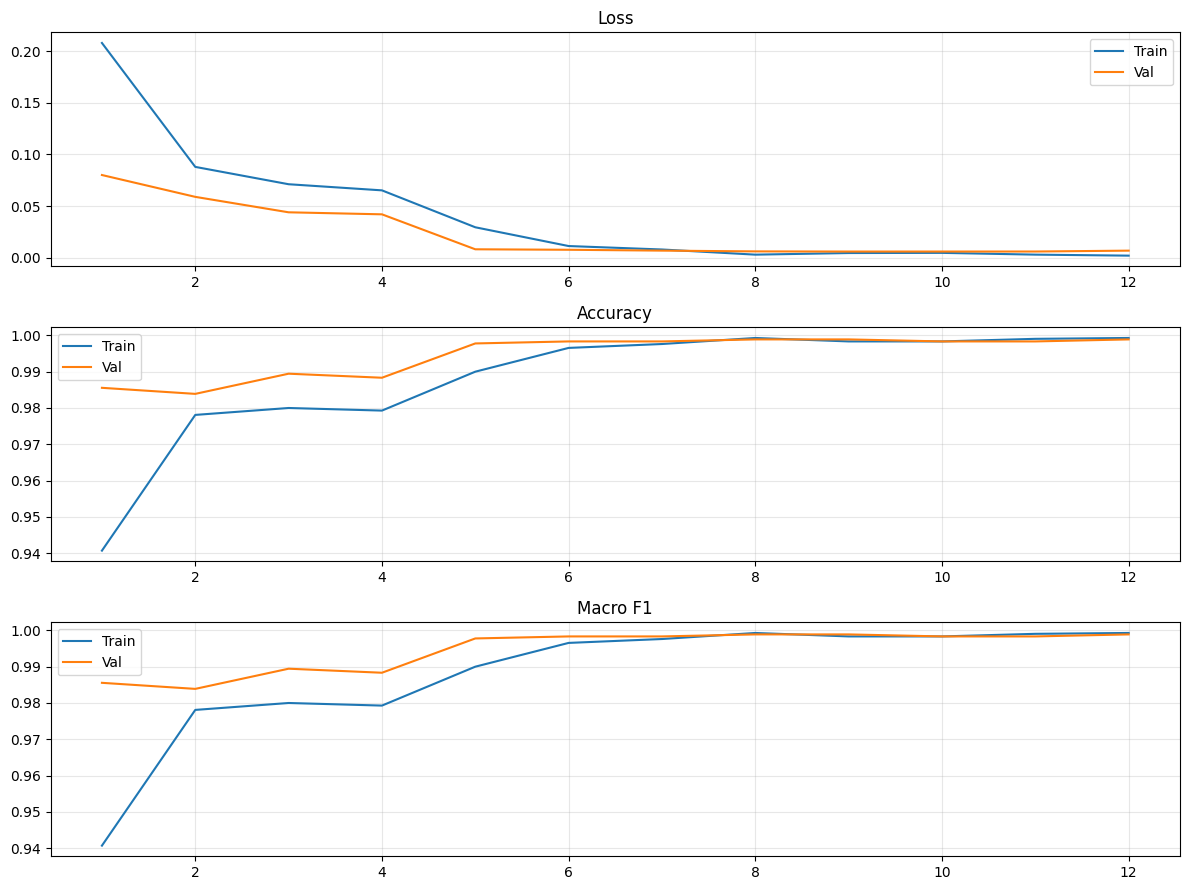

/kaggle/working/floodframe/outputs/assets/training_curves.png


In [15]:
history_df=pd.DataFrame(history); display(history_df); history_df.to_csv(REPORT_DIR/'training_history.csv',index=False)
plt.figure(figsize=(12,9))
plt.subplot(3,1,1); plt.plot(history_df.epoch,history_df.train_loss,label='Train'); plt.plot(history_df.epoch,history_df.val_loss,label='Val'); plt.title('Loss'); plt.grid(alpha=.3); plt.legend()
plt.subplot(3,1,2); plt.plot(history_df.epoch,history_df.train_accuracy,label='Train'); plt.plot(history_df.epoch,history_df.val_accuracy,label='Val'); plt.title('Accuracy'); plt.grid(alpha=.3); plt.legend()
plt.subplot(3,1,3); plt.plot(history_df.epoch,history_df.train_f1,label='Train'); plt.plot(history_df.epoch,history_df.val_f1,label='Val'); plt.title('Macro F1'); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); curve_path=ASSET_DIR/'training_curves.png'; plt.savefig(curve_path,dpi=200,bbox_inches='tight'); plt.show(); print(curve_path)

## 11. Load best checkpoint & evaluate test set

In [16]:
ckpt=torch.load(BEST_MODEL_PATH,map_location=DEVICE,weights_only=False)
best_model=efficientnet_b0(weights=None); inf=best_model.classifier[1].in_features; best_model.classifier[1]=nn.Linear(inf,len(ckpt['classes'])); best_model.load_state_dict(ckpt['model_state_dict']); best_model=best_model.to(DEVICE); best_model.eval()
# temporarily point eval helper to best model
model = best_model
te_loss,te_acc,te_f1,y_true,y_pred=eval_epoch(test_loader)
flood_idx=class_to_idx['flood']; yt=[1 if y==flood_idx else 0 for y in y_true]; yp=[1 if y==flood_idx else 0 for y in y_pred]
metrics={'test_loss':float(te_loss),'accuracy':float(te_acc),'macro_f1':float(te_f1),'flood_precision':float(precision_score(yt,yp,zero_division=0)),'flood_recall':float(recall_score(yt,yp,zero_division=0)),'flood_f1':float(f1_score(yt,yp,zero_division=0)),'best_val_f1':float(best_val_f1),'best_epoch':int(best_epoch)}
print(json.dumps(metrics,indent=2)); print(); print(classification_report(y_true,y_pred,target_names=class_names,zero_division=0))
with open(REPORT_DIR/'test_metrics.json','w',encoding='utf-8') as f: json.dump(metrics,f,indent=2)

{
  "test_loss": 0.0034085847934087117,
  "accuracy": 0.9988888888888889,
  "macro_f1": 0.9988888875171451,
  "flood_precision": 1.0,
  "flood_recall": 0.9977777777777778,
  "flood_f1": 0.9988876529477196,
  "best_val_f1": 0.9988888875171451,
  "best_epoch": 8
}

              precision    recall  f1-score   support

       flood       1.00      1.00      1.00       900
      normal       1.00      1.00      1.00       900

    accuracy                           1.00      1800
   macro avg       1.00      1.00      1.00      1800
weighted avg       1.00      1.00      1.00      1800



## 12. Confusion matrix

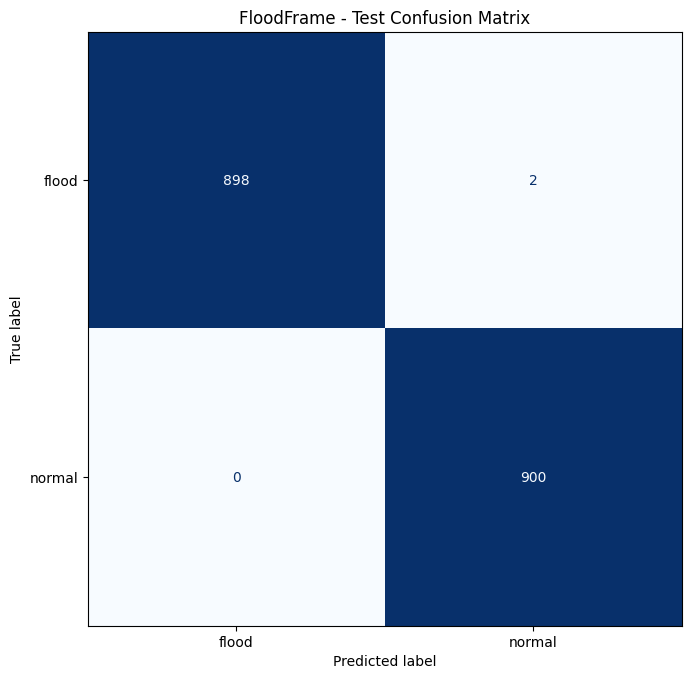

/kaggle/working/floodframe/outputs/assets/confusion_matrix.png


In [17]:
cm=confusion_matrix(y_true,y_pred); fig,ax=plt.subplots(figsize=(7,7)); disp=ConfusionMatrixDisplay(cm,display_labels=class_names); disp.plot(ax=ax,cmap='Blues',colorbar=False); ax.set_title('FloodFrame - Test Confusion Matrix'); plt.tight_layout(); cm_path=ASSET_DIR/'confusion_matrix.png'; plt.savefig(cm_path,dpi=200,bbox_inches='tight'); plt.show(); print(cm_path)

## 13. Prediction grid

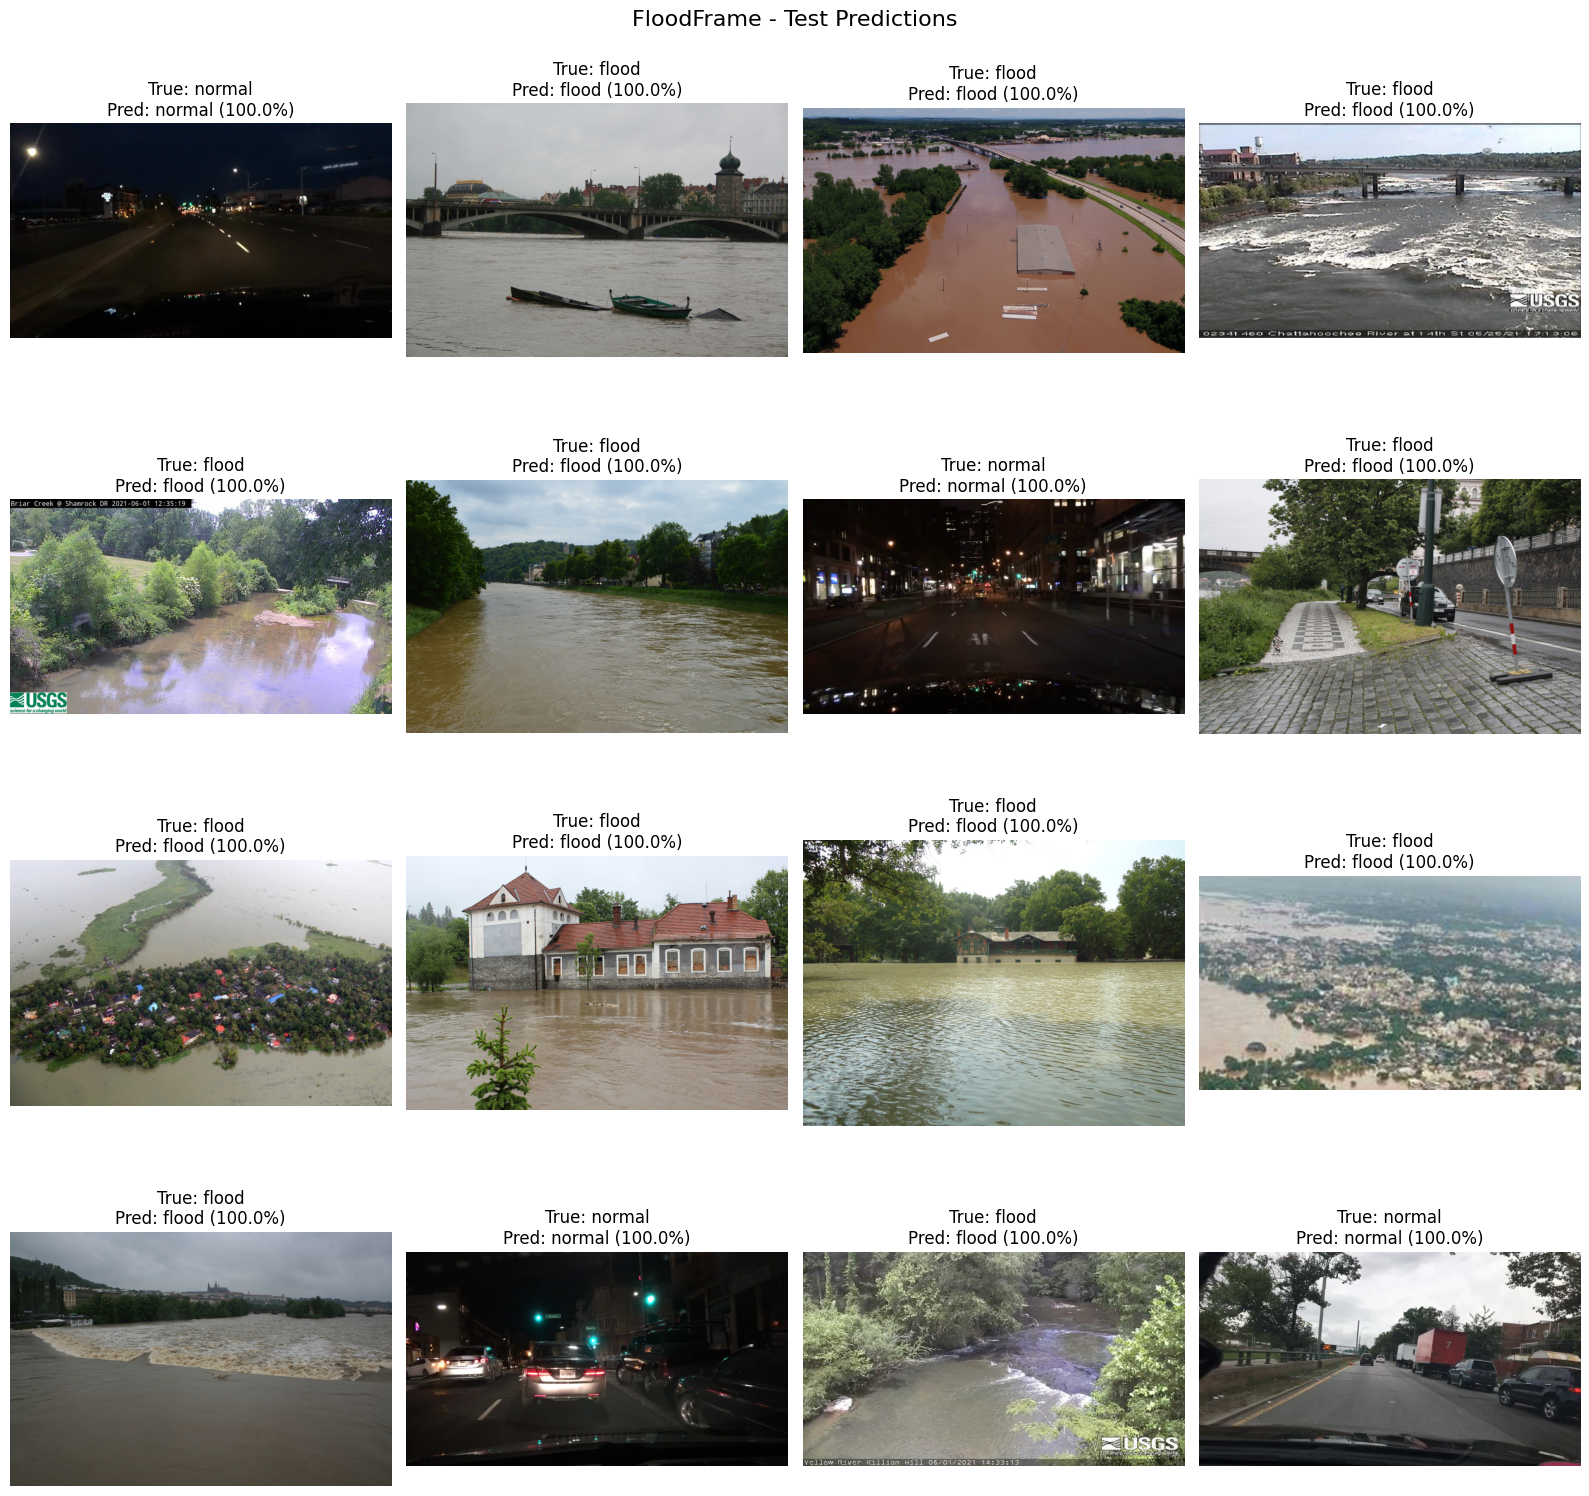

/kaggle/working/floodframe/outputs/assets/prediction_grid.png


In [18]:
@torch.no_grad()
def predict_pil(img):
    x=val_transform(img.convert('RGB')).unsqueeze(0).to(DEVICE)
    with autocast_ctx(): logits=best_model(x); probs=torch.softmax(logits,dim=1)[0]
    conf,idx=probs.max(0)
    return {'prediction':class_names[idx.item()],'confidence':float(conf.item()),'probabilities':{class_names[i]:float(probs[i].item()) for i in range(len(class_names))}}
indices=random.sample(range(len(test_dataset)),min(16,len(test_dataset))); cols=4; rows=math.ceil(len(indices)/cols); plt.figure(figsize=(16,4*rows))
for k,di in enumerate(indices,1):
    path,true_idx=test_dataset.samples[di]; img=Image.open(path).convert('RGB'); r=predict_pil(img); ax=plt.subplot(rows,cols,k); ax.imshow(img); ax.set_title(f"True: {class_names[true_idx]}\nPred: {r['prediction']} ({r['confidence']:.1%})"); ax.axis('off')
plt.suptitle('FloodFrame - Test Predictions',fontsize=16); plt.tight_layout(); pred_path=ASSET_DIR/'prediction_grid.png'; plt.savefig(pred_path,dpi=200,bbox_inches='tight'); plt.show(); print(pred_path)

## 14. Export local model

In [19]:
EXPORT_MODEL_PATH=MODEL_DIR/'floodframe_efficientnet_b0.pth'
torch.save({'model_name':'efficientnet_b0','model_state_dict':best_model.state_dict(),'classes':class_names,'class_to_idx':class_to_idx,'image_size':IMAGE_SIZE,'task':'binary_image_classification','normalization':{'mean':MEAN,'std':STD},'verified_test_metrics':metrics,'grounding_summary':grounding_summary},EXPORT_MODEL_PATH)
print('Exported:',EXPORT_MODEL_PATH,'Size MB:',EXPORT_MODEL_PATH.stat().st_size/(1024*1024))

Exported: /kaggle/working/floodframe/outputs/models/floodframe_efficientnet_b0.pth Size MB: 15.59011173248291


## 15. Final summary + ZIP

In [20]:
final_summary={'project':'FloodFrame','model':'EfficientNet-B0','task':'NORMAL vs FLOOD image classification','metrics':metrics,'classes':class_names,'limitations':grounding_summary['limitations']}
with open(REPORT_DIR/'final_summary.json','w',encoding='utf-8') as f: json.dump(final_summary,f,indent=2)
ZIP_PATH=Path('/kaggle/working/floodframe_outputs.zip')
if ZIP_PATH.exists(): ZIP_PATH.unlink()
with zipfile.ZipFile(ZIP_PATH,'w',zipfile.ZIP_DEFLATED) as zf:
    for fp in OUTPUT_DIR.rglob('*'):
        if fp.is_file(): zf.write(fp,fp.relative_to(OUTPUT_DIR))
print('='*80); print('DONE'); print('='*80); print('Download:',ZIP_PATH)
with zipfile.ZipFile(ZIP_PATH,'r') as zf:
    for n in zf.namelist(): print(' -',n)

DONE
Download: /kaggle/working/floodframe_outputs.zip
 - reports/dataset_distribution.csv
 - reports/test_metrics.json
 - reports/training_history.csv
 - reports/grounding_summary.json
 - reports/final_summary.json
 - assets/confusion_matrix.png
 - assets/prediction_grid.png
 - assets/training_curves.png
 - models/best_model.pth
 - models/floodframe_efficientnet_b0.pth


## Expected Save Version output

If the notebook reaches the final cell without error, download:

`/kaggle/working/floodframe_outputs.zip`

The ZIP contains model, metrics, training curves, confusion matrix, prediction grid, and grounding reports.